# Etapa II · Fase 1: base común

Este notebook revisa lo que generan los módulos de `src/etapa2/`. No calcula nada nuevo: carga y verifica los archivos.

| Paso | Módulo | Salida |
|---|---|---|
| Configuración | `config.py` | semilla, rutas, clases |
| Etiquetas + splits | `labels.py`, `splits.py` | `data/etapa2/labeled_documents.tsv` |
| Normalización N0/N1/N2 | `normalization.py` | `data/etapa2/normalized_variants.tsv` |
| Registro de experimentos | `tracking.py` | `results/etapa2/experiments.tsv` |

Para regenerar todo:
```bash
python -m src.etapa2.labels
python -m src.etapa2.normalization
python -m src.etapa2.tracking
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src.etapa2 import config
from src.etapa2.labels import load_raw, check_labels, build_labeled, load_labeled, cross_listing_rate
from src.etapa2.splits import check_splits
from src.etapa2.normalization import load_variants, NormalizedText
from src.etapa2.tracking import load_experiments

pd.set_option("display.max_colwidth", 120)
print("RANDOM_STATE =", config.RANDOM_STATE)
print("Clases:", config.CLASSES)

RANDOM_STATE = 0
Clases: ['cs.CL', 'cs.CV', 'cs.IR', 'cs.LG']


## 1. Política de etiqueta

- **Etiqueta:** `primary_category`, la categoría primaria que asigna arXiv.
- **Categorías secundarias** (cross-listing): se guardan en `categories` como metadato y no se usan como etiqueta. Sirven después para explicar errores.
- **Entrada `X`:** `title + ". " + abstract`.
- **`document_id`:** `arxiv_id`, leído como texto. Si se lee como número se pierden ceros: `2610.00840` → `2610.0084`.

`check_labels` falla si hay etiquetas vacías, clases inesperadas, IDs duplicados o si `primary_category` no coincide con el primer elemento de `categories`.

In [2]:
raw = load_raw()
check_labels(raw)
first = raw["categories"].str.split().str[0]
print(f"Documentos: {len(raw)}")
print(f"primary_category == categories[0]: {(raw['primary_category'] == first).sum()} / {len(raw)}")
print(f"Etiquetas vacías: {(raw['primary_category'] == '').sum()}")
raw["primary_category"].value_counts().rename("documentos").to_frame()

Documentos: 500
primary_category == categories[0]: 500 / 500
Etiquetas vacías: 0


,documentos
primary_category,
cs.CL,125
cs.CV,125
cs.IR,125
cs.LG,125


### Cross-listing por clase
Porcentaje de documentos con al menos una categoría secundaria. Una tasa alta anticipa confusiones entre clases.

In [3]:
df = load_labeled()
cross_listing_rate(df).rename("% con categoría secundaria").to_frame()

,% con categoría secundaria
label,
cs.CL,56.0
cs.CV,43.2
cs.IR,43.2
cs.LG,59.2


In [4]:
# Categorías secundarias más comunes por clase
sec = df.assign(secondary=df["categories"].str.split().str[1:]).explode("secondary").dropna(subset=["secondary"])
(sec.groupby("label")["secondary"].value_counts().groupby(level=0).head(4)
    .rename("documentos").to_frame())

documentos
label secondary            
cs.CL cs.AI              43
      cs.LG              35
      cs.IR               6
      cs.CV               4
cs.CV cs.AI              31
      cs.LG              15
      cs.RO               6
      cs.CL               5
cs.IR cs.AI              26
      cs.LG              19
      cs.CL              18
      cs.CV               5
cs.LG cs.AI              34
      stat.ML            13
      cs.CL              13
      cs.CV               7

## 2. Splits train / dev / test

Dos cortes con `train_test_split(shuffle=True, random_state=0, stratify=label)`: 70/30 y luego el 30 en 15/15. Los splits se fijan **antes de ajustar nada**.

In [5]:
table = check_splits(df)
table.loc["total"] = table.sum()
table

split,train,dev,test
label,,,
cs.CL,87,19,19
cs.CV,87,19,19
cs.IR,88,18,19
cs.LG,88,19,18
total,350,75,75


In [6]:
# Reproducibilidad: reconstruir desde el corpus crudo debe dar exactamente lo mismo
rebuilt = build_labeled(load_raw())
same = (rebuilt.reset_index(drop=True).astype(str) == df.astype(str)).all().all()
print("Splits idénticos al reconstruir:", same)
assert same

Splits idénticos al reconstruir: True


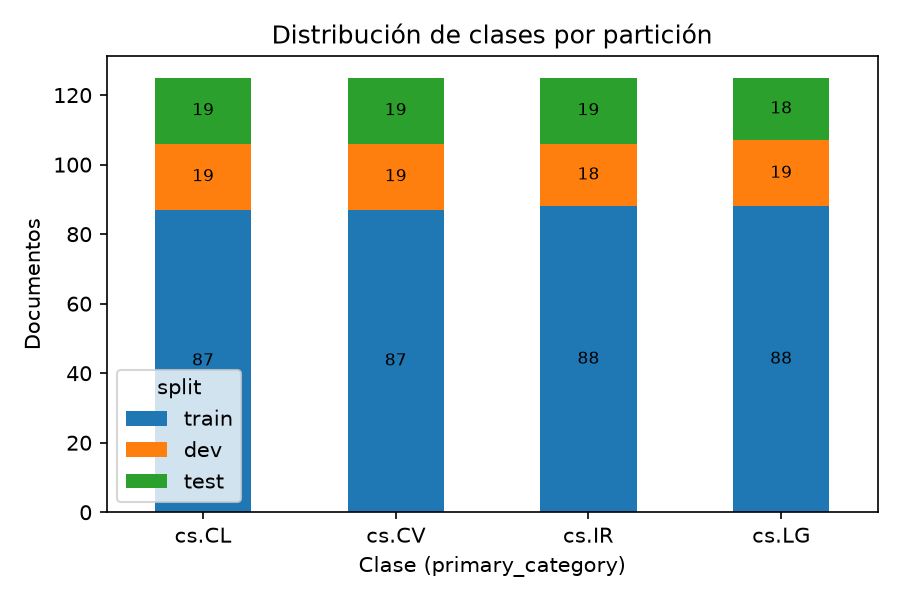

In [7]:
display(Image(filename=str(config.FIGURES_DIR / "class_distribution.png")))

In [8]:
df.head()

,document_id,text,label,categories,split
0,2610.00840,"Contextual trajectory and incremental contextual displacement: Towards using LLMs to understand dynamic, utterance-s...",cs.CL,cs.CL cs.AI,train
1,2610.00833,VERITYGATE: A Four-Gate Schema-Level Faithfulness Framework and Paired Benchmark for Grounded LLM Narrations over St...,cs.CL,cs.CL cs.LG,train
2,2610.00827,Verbalized and Internal Probabilities Are Coupled in Large Language Models. Large language models carry an internal ...,cs.CL,cs.CL cs.AI,train
3,2610.06903,Component and Dimension Sparsity in Transformer Refusal Mechanisms. Activation steering manipulates large language m...,cs.CL,cs.CL cs.AI cs.LG,train
4,2610.00795,Can large language models unlock discrete data in ophthalmic diagnostic reports?. Objective: To assess the accuracy ...,cs.CL,cs.CL,train


## 3. Normalización N0 / N1 / N2

| ID | Operaciones |
|---|---|
| N0 | Solo tokenización con spaCy (conserva mayúsculas y puntuación) |
| N1 | + minúsculas, sin puntuación ni stopwords (`token.is_stop`) |
| N2 | Normalización de la Etapa I: minúsculas, lemas, sin DET/ADP/CCONJ/SCONJ/PRON/AUX |

Se procesa cada texto una sola vez con `nlp.pipe` y se guarda la caché.

In [9]:
variants = load_variants()
assert variants["document_id"].tolist() == df["document_id"].tolist()

doc_id = df["document_id"].iloc[0]
row = variants.set_index("document_id").loc[doc_id]
print("ORIGINAL:\n", df.set_index("document_id").loc[doc_id, "text"][:400], "\n")
for name in config.NORMALIZATIONS:
    print(f"{name}:\n", row[f"text_{name.lower()}"][:400], "\n")

ORIGINAL:


 Contextual trajectory and incremental contextual displacement: Towards using LLMs to understand dynamic, utterance-specific meaning construction. Transformer-based large language models (LLMs) such as RoBERTa represent text using contextual word embeddings (CWEs), which alter the embeddings associated with each token based on surrounding context. We construct token-wise incremental trajectories by 

N0:
 Contextual trajectory and incremental contextual displacement : Towards using LLMs to understand dynamic , utterance - specific meaning construction . Transformer - based large language models ( LLMs ) such as RoBERTa represent text using contextual word embeddings ( CWEs ) , which alter the embeddings associated with each token based on surrounding context . We construct token - wise incremental  

N1:
 contextual trajectory incremental contextual displacement llms understand dynamic utterance specific meaning construction transformer based large language models llms roberta represen

In [10]:
stats = []
for name in config.NORMALIZATIONS:
    toks = variants[f"text_{name.lower()}"].str.split()
    train_toks = toks[df["split"].values == "train"]
    stats.append({
        "normalización": name,
        "tokens/doc (media)": round(toks.str.len().mean(), 1),
        "vocabulario (500 docs)": len({t for d in toks for t in d}),
        "vocabulario (solo train)": len({t for d in train_toks for t in d}),
    })
pd.DataFrame(stats).set_index("normalización")

,tokens/doc (media),vocabulario (500 docs),vocabulario (solo train)
normalización,,,
N0,257.8,12153,9974
N1,145.1,9871,8098
N2,155.7,8207,6689


N1 queda con menos tokens por documento que N2 porque `is_stop` quita más palabras que el filtro por POS. N2 tiene el vocabulario más pequeño porque la lematización junta formas (`models` → `model`).

### Transformador para los Pipeline
`NormalizedText` recibe `document_id` y devuelve el texto de la caché. Es el primer paso de cada Pipeline en la Fase 2, así la normalización se puede variar como un hiperparámetro.

In [11]:
ids = df["document_id"].head(2).tolist()
for v in config.NORMALIZATIONS:
    print(v, "→", NormalizedText(v).fit_transform(ids)[0][:90])

N0 → Contextual trajectory and incremental contextual displacement : Towards using LLMs to unde


N1 → contextual trajectory incremental contextual displacement llms understand dynamic utteranc
N2 → contextual trajectory incremental contextual displacement use llm to understand dynamic ut


## 4. Registro de experimentos
`experiments.tsv` arranca vacío. En la Fase 2 cada experimento se agrega con `log_experiment(...)`.

In [12]:
load_experiments()

,experiment_id,task,block,normalization,representation,ngram_range,svd_components,method,hyperparameters,cv_macro_f1,dev_metric,extra,selected,notes


## Resumen de la Fase 1

- 500 documentos, 125 por clase, sin etiquetas vacías ni inconsistentes.
- Splits 350 / 75 / 75, estratificados y reproducibles.
- Caché con N0, N1 y N2 para los 500 documentos.
- `experiments.tsv` listo con encabezados.

**Siguiente:** Fase 2, bloque C-1 (NB vs LR vs SVC con N2 y TF-IDF (1,1)).